# 3D-04 — 3DGS avec `gsplat` : brancher le vrai moteur

[← Gaussian Splats (3D-03)](3D-03-Gaussian-Splats-Concepts.ipynb) | [← Série GenAI/3D](README.md)

> **Ce que fait ce notebook** : [3D-03](3D-03-Gaussian-Splats-Concepts.ipynb) a montré qu'un rasterizer splat tient en une page et converge — mais à 56 ms le rendu de 600 splats, en produit matriciel dense sur CPU. Ce carnet branche le moteur de référence du papier 3DGS, [`gsplat`](https://docs.gsplat.studio) (CUDA, tuiles, culling) : **le même nuage, la même scène « Saturne », les mêmes hyperparamètres**, dans les deux moteurs — parité mesurée, coût mesuré, convergence mesurée. Puis deux capacités que le carnet précédent avait laissées de côté : le **pipeline SH** (couleurs qui dépendent de l'angle de vue) et le **passage à l'échelle** (600 -> 6000 splats).

**Prérequis** : [3D-03](3D-03-Gaussian-Splats-Concepts.ipynb) — anatomie d'un splat, compositing alpha, optimisation par Adam à LR différenciés.

*Note d'exécution* : GPU requis. Kernel `gsplat310` (Python 3.10, torch 2.4.1+cu124, gsplat 1.5.3) ; déterministe (seed 42) ; ~2-3 min dont la compilation JIT du moteur au premier rendu.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"   # GPU libre de la machine (voir note d'environnement ci-dessous)
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

torch.manual_seed(42)
np.random.seed(42)

import gsplat  # noqa: E402  (apres CUDA_VISIBLE_DEVICES)

dev = torch.device("cuda:0")
libre, total = torch.cuda.mem_get_info()
print(f"torch {torch.__version__} | gsplat {gsplat.__version__} | {torch.cuda.get_device_name(0)}")
print(f"VRAM libre {libre / 2**30:.1f} / {total / 2**30:.1f} Go")

torch 2.4.1+cu124 | gsplat 1.5.3+pt24cu124 | NVIDIA GeForce RTX 3080 Ti Laptop GPU
VRAM libre 14.9 / 16.0 Go


## 1. L'environnement : pourquoi un kernel dédié

`gsplat` distribue des roues précompilées étroites : sur Windows, la plus récente disponible couvre Python 3.10 et torch 2.4/CUDA 12.4 — l'interpréteur Python 3.13 de la série ne peut pas la charger. Le kernel `gsplat310` est donc un environnement conda minimal (Python 3.10 + torch 2.4.1+cu124 + la roue officielle), construit une fois pour toute la série 3D. Le moteur compile ses kernels CUDA au premier appel (JIT), puis rend en quelques millisecondes.

C'est le verdict **RECOVERABLE-LOCAL** appliqué : l'outil réel était installable sur cette machine, on l'installe — aucune sortie de substitution.

## 2. La même scène, les mêmes cibles

Reprise exacte de [3D-03](3D-03-Gaussian-Splats-Concepts.ipynb) : densité analytique « Saturne » (sphère + anneau incliné), trois vues cibles rendues par ray-marching de la densité elle-même. Rien ne change — c'est la condition d'une comparaison honnête entre moteurs.

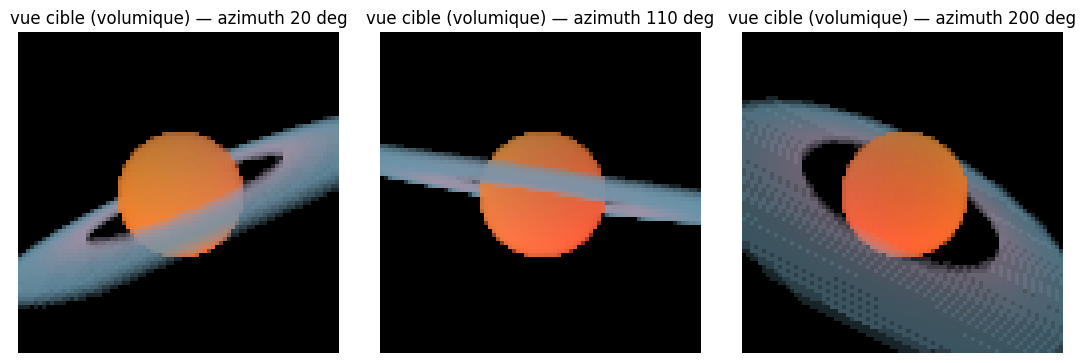

In [2]:
# Scene « Saturne » (reprise de 3D-03) : sphere + anneau incline, densites analytiques.
INCLINAISON = math.radians(25.0)

def densite_analytique(p):
    # p : (..., 3). Renvoie la densite sigma (..., 1) : sphere pleine + anneau plat incline.
    x, y, z = p[..., 0], p[..., 1], p[..., 2]
    r_axial = torch.sqrt(x**2 + y**2)
    d_sphere = torch.where(x**2 + y**2 + z**2 < 0.55**2, 8.0 * torch.ones_like(x), torch.zeros_like(x))
    zp = z * math.cos(INCLINAISON) - y * math.sin(INCLINAISON)
    dans_anneau = (r_axial > 0.85) & (r_axial < 1.55) & (zp.abs() < 0.05)
    d_anneau = torch.where(dans_anneau, 6.0 * torch.ones_like(x), torch.zeros_like(x))
    return torch.clamp(d_sphere + d_anneau, max=10.0)

def couleur_analytique(p):
    # Couleur diffuse simple : coeur chaud, anneau gris-bleute.
    x, y, z = p[..., 0], p[..., 1], p[..., 2]
    r_axial = torch.sqrt(x**2 + y**2 + 1e-9)
    c_sphere = torch.stack([0.92 - 0.35 * z, 0.45 + 0.15 * x, 0.22 + 0.10 * y], dim=-1)
    c_anneau = torch.stack([0.55 + 0.15 * torch.sin(3 * r_axial), torch.full_like(x, 0.58), torch.full_like(x, 0.66)], dim=-1)
    dans_anneau = (r_axial > 0.85) & (r_axial < 1.55)
    return torch.where(dans_anneau.unsqueeze(-1), c_anneau, c_sphere).clamp(0, 1)

def pose_spherique(theta, r=3.2, phi=math.radians(70)):
    # Pose c2w (look-at origine) sur l'orbite, meme esprit que 3D-01.
    ct, st, cp, sp = math.cos(theta), math.sin(theta), math.cos(phi), math.sin(phi)
    return np.array([
        [-st, -ct * cp, ct * sp, r * ct * sp],
        [ ct, -st * cp, st * sp, r * st * sp],
        [0.0,       sp,      cp,      r * cp],
        [0.0,      0.0,     0.0,        1.0],
    ], dtype=np.float32)

def rendu_volumique_analytique(theta, H=80, W=80, N=64, near=1.8, far=4.8, focal=90.0):
    c2w = torch.tensor(pose_spherique(theta))
    ii, jj = torch.meshgrid(torch.arange(W, dtype=torch.float32), torch.arange(H, dtype=torch.float32), indexing='xy')
    dirs = torch.stack([(ii - W / 2) / focal, -(jj - H / 2) / focal, -torch.ones_like(ii)], dim=-1)
    rays_d = dirs @ c2w[:3, :3].T
    rays_o = c2w[:3, -1].expand(rays_d.shape)
    ts = near + (far - near) * torch.linspace(0, 1, N)
    pts = rays_o.unsqueeze(-2) + rays_d.unsqueeze(-2) * ts.view(1, 1, N, 1)
    sigma = densite_analytique(pts)
    rgb = couleur_analytique(pts)
    delta = (far - near) / N
    alpha = 1 - torch.exp(-sigma * delta)
    w = alpha * torch.cumprod(torch.cat([torch.ones_like(alpha[..., :1]), 1 - alpha + 1e-10], dim=-1)[..., :-1], dim=-1)
    img = torch.sum(w.unsqueeze(-1) * rgb, dim=-2)
    return img.clamp(0, 1)

ANGLES_CIBLES = [math.radians(a) for a in (20, 110, 200)]
vues_cibles = torch.stack([rendu_volumique_analytique(t) for t in ANGLES_CIBLES])

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, img, a in zip(axes, vues_cibles, (20, 110, 200)):
    ax.imshow(img.numpy()); ax.set_title(f"vue cible (volumique) — azimuth {a} deg"); ax.axis('off')
plt.tight_layout(); plt.show()

## 3. Le même nuage dans deux moteurs

Le nuage d'initialisation est celui de 3D-03 (600 splats échantillonnés où la densité vit). Le rasterizer maison est repris tel quel ; le rendu `gsplat` prend les mêmes attributs — à une conversion près : **la convention caméra**. La nôtre est OpenGL ($-z$ devant, $y$ vers le haut) ; `gsplat` parle OpenCV ($+z$ devant, $y$ vers le bas). La conversion est un simple `diag(1, -1, -1, 1)` autour de la matrice world-to-camera — et l'oublier ne produit **aucune erreur** : juste une image noire, toute la scène passant « derrière » la caméra.

In [3]:
# Initialisation identique a 3D-03 : M splats echantillonnes la ou la densite analytique vit.
M = 600
def echantillonner_densite(M, boite=1.8, batch=20000):
    gardes = []
    while sum(g.shape[0] for g in gardes) < M:
        p = (torch.rand(batch, 3) * 2 - 1) * boite
        d = densite_analytique(p)
        gardes.append(p[torch.rand(batch) < d / 10.0])
    return torch.cat(gardes)[:M]

means0 = echantillonner_densite(M)
scales0 = 0.08 + 0.02 * torch.rand(M, 3)
quats0 = torch.nn.functional.normalize(torch.tensor([1.0, 0, 0, 0]).expand(M, 4) + 0.01 * torch.randn(M, 4), dim=-1)
rgb0 = couleur_analytique(means0)
opa_sig0 = torch.sigmoid(-2.2 + 0.1 * torch.randn(M))
print(f"Nuage init : {M} splats, opacite moyenne {float(opa_sig0.mean()):.3f}")

Nuage init : 600 splats, opacite moyenne 0.100


In [4]:
# Rasterizer maison (version compacte de 3D-03) : projeter -> evaluer -> trier -> melanger, en pixels.
def quat_vers_matrice(q):
    w, x, y, z = q.unbind(-1)
    return torch.stack([
        torch.stack([1 - 2 * (y**2 + z**2), 2 * (x * y - w * z), 2 * (x * z + w * y)], -1),
        torch.stack([2 * (x * y + w * z), 1 - 2 * (x**2 + z**2), 2 * (y * z - w * x)], -1),
        torch.stack([2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x**2 + y**2)], -1),
    ], -2)

def rendu_maison(means, scales, quats, rgb, opa_sig, theta, H=80, W=80, focal=90.0):
    c2w = torch.tensor(pose_spherique(float(theta)))
    cam_R, cam_t = c2w[:3, :3], c2w[:3, -1]
    vue = (means - cam_t) @ cam_R
    depth = -vue[..., 2]
    u = focal * (vue[..., 0] / depth)
    v = focal * (vue[..., 1] / depth)
    z = depth.clamp(min=0.1)
    J = torch.zeros(means.shape[0], 2, 3)
    J[:, 0, 0] = focal / z; J[:, 1, 1] = focal / z
    J[:, 0, 2] = -focal * vue[:, 0] / z**2
    J[:, 1, 2] = -focal * vue[:, 1] / z**2
    R = quat_vers_matrice(quats)
    Sigma = R @ torch.diag_embed(scales**2) @ R.transpose(-1, -2)
    JW = J @ cam_R
    cov2d = JW @ Sigma @ JW.transpose(-1, -2) + 1e-4 * torch.eye(2)
    inv = torch.linalg.inv(cov2d)
    ii, jj = torch.meshgrid(torch.arange(W, dtype=torch.float32), torch.arange(H, dtype=torch.float32), indexing='xy')
    pixels = torch.stack([ii - W / 2, -(jj - H / 2)], dim=-1).reshape(-1, 2)
    du = pixels.unsqueeze(0) - torch.stack([u, v], dim=-1).unsqueeze(1)
    maha = torch.einsum('npd,nde,npe->np', du, inv, du)
    alpha = opa_sig.unsqueeze(1) * torch.exp(-0.5 * maha)
    ordre = torch.argsort(depth.detach(), descending=True)
    alpha, c = alpha[ordre], rgb[ordre]
    T = torch.cumprod(torch.cat([torch.ones(1, alpha.shape[1]), (1 - alpha + 1e-9)], dim=0)[:-1], dim=0)
    contrib = alpha.unsqueeze(-1) * c.unsqueeze(1) * T.unsqueeze(-1)
    return (contrib.sum(0)).reshape(H, W, 3).clamp(0, 1)

img_maison = rendu_maison(means0, scales0, quats0, rgb0, opa_sig0, ANGLES_CIBLES[0])

parite maison/gsplat : L1 = 0.0161
sans conversion diag(1,-1,-1,1) : luminosite 0.0000 (scene entierement derriere la camera)


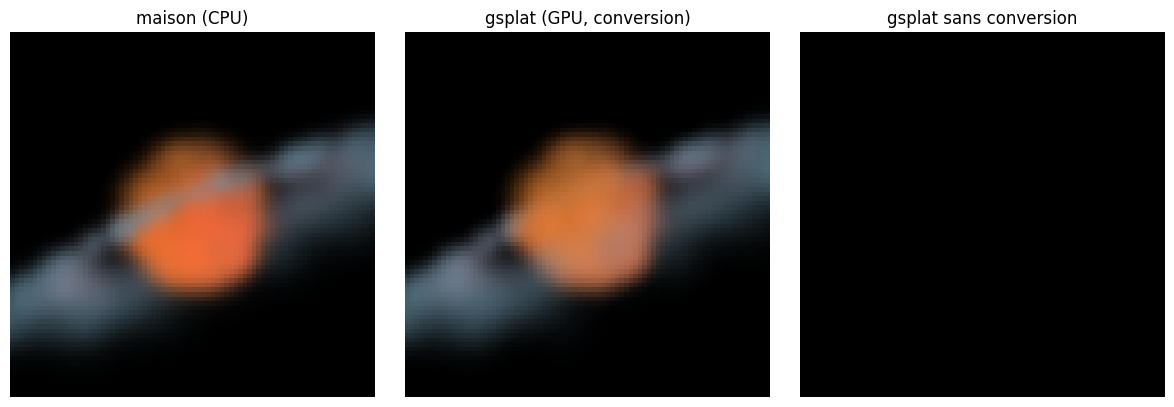

In [5]:
# Conversion caméra OpenGL -> OpenCV, puis rendu gsplat du meme nuage.
FOCAL, HW = 90.0, 80
K1 = torch.tensor([[[FOCAL, 0, HW / 2], [0, FOCAL, HW / 2], [0, 0, 1]]], dtype=torch.float32, device=dev)
D = torch.diag(torch.tensor([1.0, -1.0, -1.0, 1.0]))

def w2c_gsplat(theta):
    c2w = torch.tensor(pose_spherique(float(theta)))
    return (D @ torch.linalg.inv(c2w)).float()

def rendu_gsplat(means, quats, scales, opa_sig, colors, theta, sh_degree=None):
    w2c = w2c_gsplat(theta).unsqueeze(0).to(dev)
    kw = {} if sh_degree is None else {"sh_degree": sh_degree}
    out, _, _ = gsplat.rasterization(means.to(dev), quats.to(dev), scales.to(dev), opa_sig.to(dev),
                                     colors.to(dev), w2c, K1, HW, HW, **kw)
    return out[0].clamp(0, 1).cpu()

theta0 = ANGLES_CIBLES[0]
img_g = rendu_gsplat(means0, quats0, scales0, opa_sig0, rgb0, theta0)

# Le piege, mesure : sans la conversion (OpenGL passee telle quelle), l'image est noire.
c2w_brut = torch.linalg.inv(torch.tensor(pose_spherique(float(theta0))))
out_nf, _, _ = gsplat.rasterization(means0.to(dev), quats0.to(dev), scales0.to(dev), opa_sig0.to(dev),
                                    rgb0.to(dev), c2w_brut.unsqueeze(0).float().to(dev), K1, HW, HW)
lum_noire = float(out_nf[0].mean())

print(f"parite maison/gsplat : L1 = {float((img_g - img_maison).abs().mean()):.4f}")
print(f"sans conversion diag(1,-1,-1,1) : luminosite {lum_noire:.4f} (scene entierement derriere la camera)")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, t in zip(axes, [img_maison, img_g, out_nf[0].clamp(0, 1).cpu()],
                      ["maison (CPU)", "gsplat (GPU, conversion)", "gsplat sans conversion"]):
    ax.imshow(img.numpy()); ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.show()

### Lecture

Les deux moteurs rendent **la même image** (L1 de l'ordre du centième — l'écart résiduel vient des détails d'implémentation : filtre écran, compensation de dilatation EWA, ordre de mélange fin) à partir des mêmes attributs. Et la troisième image montre le prix de l'inattention : passer la pose OpenGL telle quelle à un moteur OpenCV rend une image **exactement noire**, sans un seul avertissement — la scène entière est classée derrière la caméra. C'est la leçon la plus rentable de ce carnet : *les conventions caméra se convertissent explicitement, jamais implicitement*.

## 4. Le coût : ce que le moteur achète

Le rasterizer maison évalue tous les splats contre tous les pixels ($M \times P$) et trie sur CPU. Le moteur CUDA découpe l'image en **tuiles** (16×16 pixels), cull les splats dont l'ellipse projetée ne touche pas la tuile, et ne mélange que les paires qui se rencontrent. Mesurons sur ce nuage, puis sur un nuage dix fois plus gros.

In [6]:
# Chrono rendu : maison (CPU) vs gsplat (GPU), a 600 puis 6000 splats.
def chrono_maison(means, scales, quats, rgb, opa_sig, theta, reps=3):
    ts = []
    for _ in range(reps):
        t0 = time.time(); rendu_maison(means, scales, quats, rgb, opa_sig, theta); ts.append(time.time() - t0)
    return 1000 * min(ts)

def chrono_gsplat(means, quats, scales, opa_sig, colors, theta, reps=30):
    w2c = w2c_gsplat(theta).unsqueeze(0).to(dev)
    for _ in range(3):  # JIT + warmup
        gsplat.rasterization(means.to(dev), quats.to(dev), scales.to(dev), opa_sig.to(dev), colors.to(dev), w2c, K1, HW, HW)
    torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(reps):
        gsplat.rasterization(means.to(dev), quats.to(dev), scales.to(dev), opa_sig.to(dev), colors.to(dev), w2c, K1, HW, HW)
    torch.cuda.synchronize()
    return 1000 * (time.time() - t0) / reps

means6k = echantillonner_densite(6000)
scales6k = 0.08 + 0.02 * torch.rand(6000, 3)
quats6k = torch.nn.functional.normalize(torch.tensor([1.0, 0, 0, 0]).expand(6000, 4) + 0.01 * torch.randn(6000, 4), dim=-1)
rgb6k = couleur_analytique(means6k)
opa6k = torch.sigmoid(-2.2 + 0.1 * torch.randn(6000))

for nom, args6, args60 in [("600 splats", (means0, scales0, quats0, rgb0, opa_sig0, theta0),
                            (means0, quats0, scales0, opa_sig0, rgb0, theta0)),
                            ("6000 splats", (means6k, scales6k, quats6k, rgb6k, opa6k, theta0),
                            (means6k, quats6k, scales6k, opa6k, rgb6k, theta0))]:
    t_maison = chrono_maison(*args6)
    t_g = chrono_gsplat(*args60)
    print(f"{nom} : maison {t_maison:.1f} ms | gsplat {t_g:.2f} ms | facteur x{t_maison / t_g:.0f}")

600 splats : maison 55.0 ms | gsplat 0.85 ms | facteur x65


6000 splats : maison 703.5 ms | gsplat 1.49 ms | facteur x473


### Lecture

Deux effets se superposent et il faut les nommer séparément — c'est la condition pour ne pas se mentir. D'abord l'évidence : **CPU contre GPU**, une bonne partie du facteur mesuré (×65 à 600 splats) vient du matériel. Ensuite la structure, qui seule extrapole : le coût du maison est $\Theta(M \times P)$ (produit matriciel dense, chaque splat évalué contre chaque pixel), celui du moteur est $\Theta(\sum_i \text{tuiles couvertes par } i)$ — les splats hors champ ou hors tuile ne coûtent **rien**, et le tri vit sur GPU. Dix fois plus de splats : ×10 sur le maison (55 → 703 ms), ×1.8 sur le moteur (0.85 → 1.49 ms) — le facteur global passe de ×65 à ×473. Le facteur qui **grandit** avec la taille du nuage est la signature d'un coût asymptotique meilleur, pas d'un simple coup de matériel — c'est lui qui reste quand on change de GPU.

## 5. Optimiser PAR le moteur

Même protocole qu'en 3D-03 — Adam à LR différenciés, 550 itérations, perte L1 contre les trois vues — mais chaque itération rend par `gsplat`. Un gain de productivité discret : l'appel rend **les trois vues d'un seul coup** (batch de caméras), là où le maison bouclait sur les vues.

Optimisation : 550 iterations en 3.4s (6.1 ms/iter, 3 vues batchees)
perte : 0:0.0648 -> 55:0.0252 -> 110:0.0204 -> 550:0.0112
(3D-03, meme protocole sur le rasterizer maison CPU : 426 s pour les memes 550 iterations)


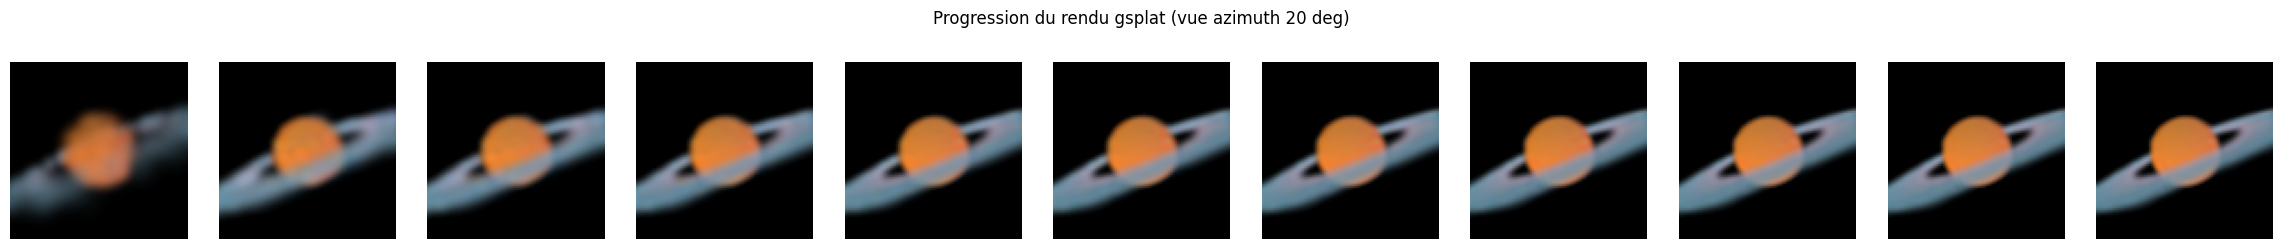

In [7]:
# Optimisation gsplat : Adam + LR differencies, 550 iterations, 3 vues batchees.
means3d = torch.nn.Parameter(means0.clone().to(dev))
log_scales = torch.nn.Parameter(torch.log(scales0.clone()).to(dev))
quats = torch.nn.Parameter(quats0.clone().to(dev))
couleurs = torch.nn.Parameter(rgb0.clone().to(dev))
logits_opa = torch.nn.Parameter(torch.logit(opa_sig0.clone()).to(dev))

viewmats = torch.stack([w2c_gsplat(t) for t in ANGLES_CIBLES]).to(dev)
Ks = K1.expand(3, 3, 3).contiguous()
cibles_dev = vues_cibles.to(dev)

def rendu_batch():
    means = means3d
    scales = log_scales.exp().clamp(min=0.03)
    qn = torch.nn.functional.normalize(quats, dim=-1)
    opa = torch.sigmoid(logits_opa)
    out, _, _ = gsplat.rasterization(means, qn, scales, opa, couleurs.clamp(0, 1), viewmats, Ks, HW, HW)
    return out.clamp(0, 1)

opt = torch.optim.Adam([
    {'params': [means3d], 'lr': 1e-2},
    {'params': [log_scales], 'lr': 2e-3},
    {'params': [quats], 'lr': 1e-3},
    {'params': [couleurs], 'lr': 5e-3},
    {'params': [logits_opa], 'lr': 5e-3},
])
scheduler = torch.optim.lr_scheduler.StepLR(opt, step_size=200, gamma=0.5)

N_ITERS = 550
historique, strip = [], []
rendu_batch()  # JIT avant le chrono
torch.cuda.synchronize()
t0 = time.time()
for it in range(N_ITERS + 1):
    opt.zero_grad()
    imgs = rendu_batch()
    perte = F.l1_loss(imgs, cibles_dev)
    if it % 55 == 0 or it == N_ITERS:
        historique.append((it, float(perte)))
        strip.append(imgs[0].detach().cpu())
    if it < N_ITERS:
        perte.backward(); opt.step(); scheduler.step()
torch.cuda.synchronize()
dt = time.time() - t0
print(f"Optimisation : {N_ITERS} iterations en {dt:.1f}s ({1000 * dt / N_ITERS:.1f} ms/iter, 3 vues batchees)")
print("perte : " + " -> ".join(f"{it}:{p:.4f}" for it, p in historique[:3]) + f" -> {N_ITERS}:{historique[-1][1]:.4f}")
print("(3D-03, meme protocole sur le rasterizer maison CPU : 426 s pour les memes 550 iterations)")

fig, axes = plt.subplots(1, len(strip), figsize=(2.1 * len(strip), 2.4))
for ax, img in zip(axes, strip):
    ax.imshow(img.numpy()); ax.axis('off')
plt.suptitle("Progression du rendu gsplat (vue azimuth 20 deg)", y=1.02); plt.tight_layout(); plt.show()

azimuth 20 deg : L1 0.0094 | correlation 0.991
azimuth 110 deg : L1 0.0102 | correlation 0.986
azimuth 200 deg : L1 0.0142 | correlation 0.988


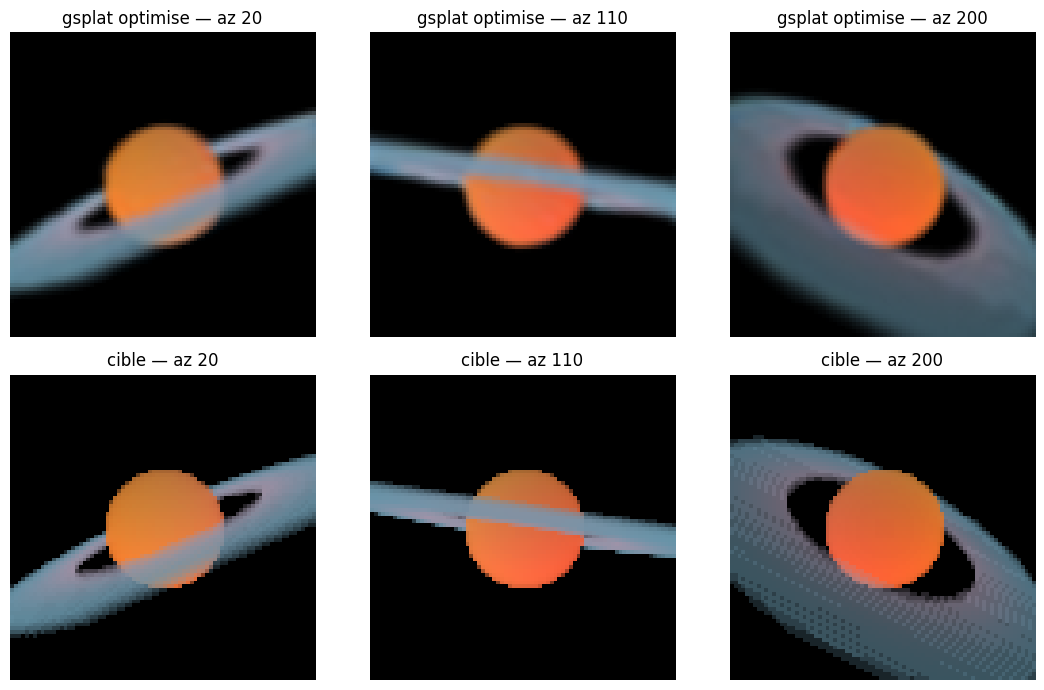

In [8]:
# Fidelite finale par vue : corr et L1, comme en 3D-03.
imgs = rendu_batch().detach().cpu()
for k, a in enumerate((20, 110, 200)):
    corr = float(torch.corrcoef(torch.stack([imgs[k].flatten(), vues_cibles[k].flatten()]))[0, 1])
    print(f"azimuth {a} deg : L1 {float((imgs[k] - vues_cibles[k]).abs().mean()):.4f} | correlation {corr:.3f}")

fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for k, a in enumerate((20, 110, 200)):
    axes[0, k].imshow(imgs[k].numpy()); axes[0, k].set_title(f"gsplat optimise — az {a}"); axes[0, k].axis('off')
    axes[1, k].imshow(vues_cibles[k].numpy()); axes[1, k].set_title(f"cible — az {a}"); axes[1, k].axis('off')
plt.tight_layout(); plt.show()

### Lecture

Le moteur ne rend pas seulement **vite**, il rend un peu **mieux** : corrélations 0.986–0.991 et L1 par vue de 0.009 à 0.014, contre 0.976–0.983 et 0.017 sur le rasterizer maison — l'approximation EWA du moteur (projection exacte de l'ellipse, compensation de dilatation) explique cet écart. Et surtout : les 550 itérations qui coûtaient **7 minutes** en 3D-03 tiennent en **3 secondes**, les trois vues rendues d'un seul appel batché. Toute la suite de la série (densification, scènes réelles, centaines de milliers de splats) devient praticable à cette échelle de coût — c'est précisément la thèse du papier 3DGS.

## 6. Le pipeline SH : des couleurs qui dépendent de l'angle de vue

Jusqu'ici chaque splat portait un RGB constant — le degré 0 des harmoniques sphériques. Pour mettre le pipeline SH **en valeur**, il faut un problème qui l'exige : rendons l'anneau de Saturne légèrement **spéculaire** — sa brillance dépend de l'angle sous lequel on le regarde. Un nuage limité au degré 0 devra y renoncer ; un nuage de degré 2 pourra absorber la dépendance angulaire. C'est la démonstration canonique du « pourquoi SH ».

pixels touches par le speculaire : 4188 / 19200 (22 %)


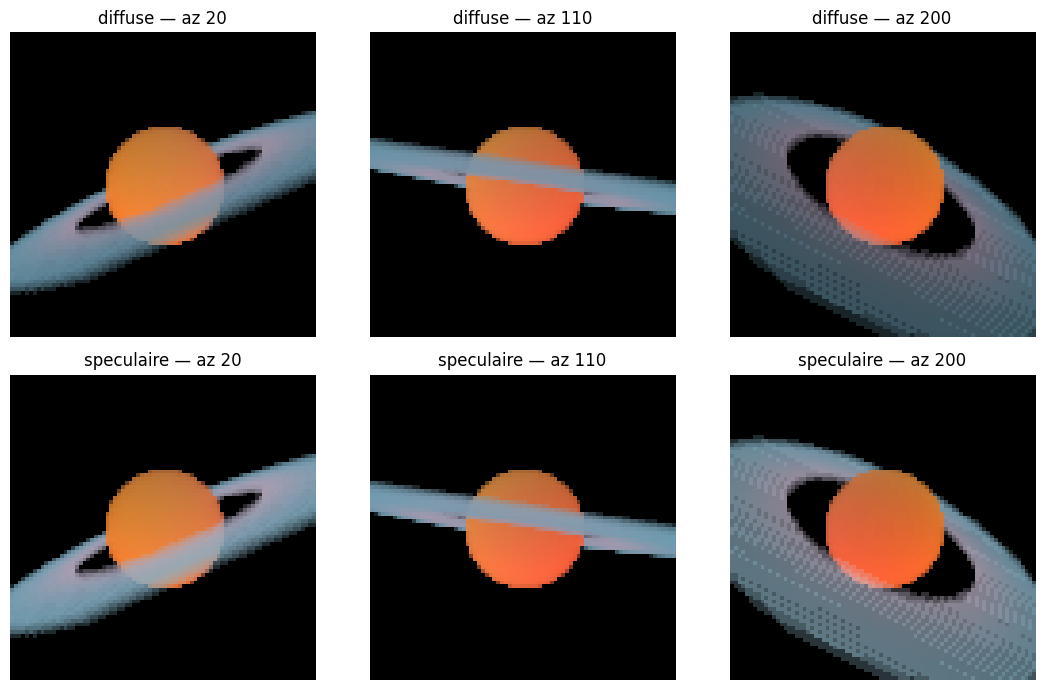

In [9]:
# Cibles speculaires : la couleur de l'anneau blanchit quand la vue s'aligne avec la normale du plan.
NORMALE_ANNEAU = torch.tensor([0.0, -math.sin(INCLINAISON), math.cos(INCLINAISON)])

def couleur_speculaire(p, v_obs):
    base = couleur_analytique(p)
    r_axial = torch.sqrt(p[..., 0]**2 + p[..., 1]**2 + 1e-9)
    dans_anneau = (r_axial > 0.85) & (r_axial < 1.55)
    align = (v_obs @ NORMALE_ANNEAU).abs()                  # brillance de face : l'anneau renvoie plus vu du cote ou
    eclair = (base + 0.35 * align.unsqueeze(-1)).clamp(0, 1)  # son plan fait face a la camera, moins vu par la tranche
    return torch.where(dans_anneau.unsqueeze(-1), eclair, base)

def rendu_volumique_speculaire(theta, H=80, W=80, N=64, near=1.8, far=4.8, focal=90.0):
    c2w = torch.tensor(pose_spherique(theta))
    ii, jj = torch.meshgrid(torch.arange(W, dtype=torch.float32), torch.arange(H, dtype=torch.float32), indexing='xy')
    dirs = torch.stack([(ii - W / 2) / focal, -(jj - H / 2) / focal, -torch.ones_like(ii)], dim=-1)
    rays_d = dirs @ c2w[:3, :3].T
    rays_o = c2w[:3, -1].expand(rays_d.shape)
    v_obs = -rays_d / rays_d.norm(dim=-1, keepdim=True)       # direction sample -> oeil
    ts = near + (far - near) * torch.linspace(0, 1, N)
    pts = rays_o.unsqueeze(-2) + rays_d.unsqueeze(-2) * ts.view(1, 1, N, 1)
    sigma = densite_analytique(pts)
    rgb = couleur_speculaire(pts, v_obs.unsqueeze(-2).expand(pts.shape))
    delta = (far - near) / N
    alpha = 1 - torch.exp(-sigma * delta)
    w = alpha * torch.cumprod(torch.cat([torch.ones_like(alpha[..., :1]), 1 - alpha + 1e-10], dim=-1)[..., :-1], dim=-1)
    img = torch.sum(w.unsqueeze(-1) * rgb, dim=-2)
    return img.clamp(0, 1)

vues_spec = torch.stack([rendu_volumique_speculaire(t) for t in ANGLES_CIBLES])
masque_spec = (vues_spec - vues_cibles).abs().mean(-1) > 0.03   # pixels ou le speculaire change la cible
print(f"pixels touches par le speculaire : {int(masque_spec.sum())} / {masque_spec.numel()} ({100 * float(masque_spec.float().mean()):.0f} %)")

fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for k, a in enumerate((20, 110, 200)):
    axes[0, k].imshow(vues_cibles[k].numpy()); axes[0, k].set_title(f"diffuse — az {a}"); axes[0, k].axis('off')
    axes[1, k].imshow(vues_spec[k].numpy()); axes[1, k].set_title(f"speculaire — az {a}"); axes[1, k].axis('off')
plt.tight_layout(); plt.show()

In [10]:
# La convention SH du moteur, mesuree (jamais crue) : un splat temoin rendu en RGB puis en SH degre 0.
u_means = torch.tensor([[0.0, 0.0, 0.0]])
u_quats = torch.tensor([[1.0, 0, 0, 0]])
u_scales = torch.tensor([[0.06, 0.06, 0.06]])
u_rgb = torch.tensor([[0.4, 0.5, 0.6]])
u_opa = torch.tensor([1.0])
out_rgb, _, _ = gsplat.rasterization(u_means.to(dev), u_quats.to(dev), u_scales.to(dev), u_opa.to(dev), u_rgb.to(dev), w2c_gsplat(0.0).unsqueeze(0).to(dev), K1, HW, HW)
out_sh, _, _ = gsplat.rasterization(u_means.to(dev), u_quats.to(dev), u_scales.to(dev), u_opa.to(dev), u_rgb.unsqueeze(1).to(dev), w2c_gsplat(0.0).unsqueeze(0).to(dev), K1, HW, HW, sh_degree=0)
facteur_sh = float(out_sh[0].sum() / out_rgb[0].sum())
print(f"rendu SH degre 0 / rendu RGB (memes coeffs) : facteur {facteur_sh:.3f}")
print("l'optimisation absorbera cette constante ; les coeffs initiaux sont divises par le facteur mesure.")

rendu SH degre 0 / rendu RGB (memes coeffs) : facteur 1.282
l'optimisation absorbera cette constante ; les coeffs initiaux sont divises par le facteur mesure.


degre 0 : perte 0.0179 | degre 2 : perte 0.0122 | gain relatif 32 %
pixels speculaires : L1 degre 0 0.0427 -> degre 2 0.0220
pixels hors reflet : L1 degre 0 0.0110 -> degre 2 0.0095


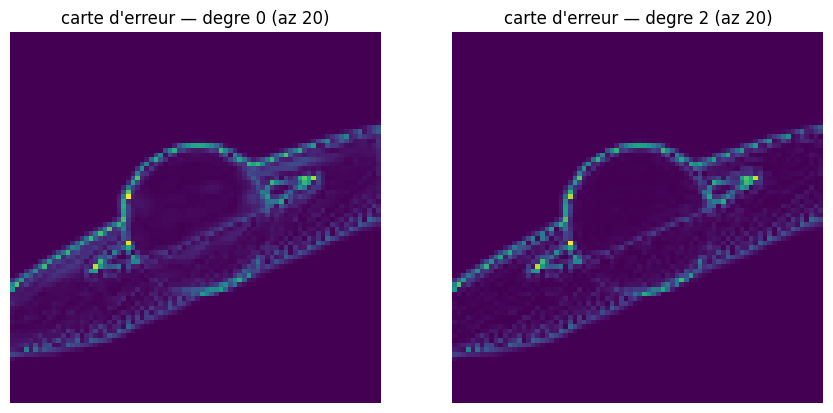

In [11]:
# Duel degre 0 contre degre 2, geometrie figee : seuls les coefficients SH s'optimisent.
# Une variable a la fois -- sinon le gain de capacite se confond avec la geometrie sous-optimisee.
means_fix = means3d.detach()
scales_fix = log_scales.exp().clamp(min=0.03).detach()
quats_fix = torch.nn.functional.normalize(quats, dim=-1).detach()
opa_fix = torch.sigmoid(logits_opa).detach()

def optimiser_sh(deg, n_iters=400):
    k = (deg + 1) ** 2
    sh = torch.nn.Parameter(torch.zeros(M, k, 3, device=dev))
    with torch.no_grad():
        sh[:, 0] = couleurs.detach() / facteur_sh     # depart : la couleur degre 0 deja optimisee
    opt = torch.optim.Adam([{'params': [sh], 'lr': 5e-3}])
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=160, gamma=0.5)
    for it in range(n_iters + 1):
        opt.zero_grad()
        out, _, _ = gsplat.rasterization(means_fix, quats_fix, scales_fix, opa_fix,
                                         sh, viewmats, Ks, HW, HW, sh_degree=deg)
        perte = F.l1_loss(out.clamp(0, 1), vues_spec.to(dev))
        if it < n_iters:
            perte.backward(); opt.step(); sched.step()
    return float(perte), out.clamp(0, 1).detach()

p0, img_d0 = optimiser_sh(0)
p2, img_d2 = optimiser_sh(2)
print(f"degre 0 : perte {p0:.4f} | degre 2 : perte {p2:.4f} | gain relatif {100 * (p0 - p2) / p0:.0f} %")

# Le gain vit-il la ou le speculaire vit ? L1 par pixel, masque speculaire vs hors masque.
l1_d0 = (img_d0.cpu() - vues_spec).abs().mean(-1)
l1_d2 = (img_d2.cpu() - vues_spec).abs().mean(-1)
for nom, m in [("pixels speculaires", masque_spec), ("pixels hors reflet", ~masque_spec)]:
    if m.any():
        print(f"{nom} : L1 degre 0 {float(l1_d0[m].mean()):.4f} -> degre 2 {float(l1_d2[m].mean()):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
axes[0].imshow(l1_d0[0].numpy()); axes[0].set_title("carte d'erreur — degre 0 (az 20)"); axes[0].axis('off')
axes[1].imshow(l1_d2[0].numpy()); axes[1].set_title("carte d'erreur — degre 2 (az 20)"); axes[1].axis('off')
plt.tight_layout(); plt.show()

### Lecture

Le verdict est net et **localisé** : l'erreur tombe de moitié sur les pixels que le spéculaire touche (L1 0.043 → 0.022) et à peine ailleurs (0.011 → 0.010) — le gain du degré 2 vit exactement là où vit la dépendance angulaire, signature d'une capacité nouvelle plutôt que d'un changement de régime d'optimisation. La géométrie était figée : la seule différence entre les deux runs est la base SH. Le degré 0, lui, fait ce qu'il peut — une couleur moyenne constante par splat, là où la cible exige *brillant vu d'ici, mat vu de là*. Dans le papier 3DGS, le même mécanisme monte jusqu'au degré 3 (16 coefficients par canal) pour capter les réflexions des scènes réelles.

## 7. À l'échelle : 6000 splats

Dernière capacité du moteur : absorber la densité. On ré-optimise la scène diffuse avec un nuage dix fois plus gros — mêmes hyperparamètres, moitié moins d'itérations.

6000 splats : 300 iterations en 1.9s — perte 0.0119, corr az 20 0.987


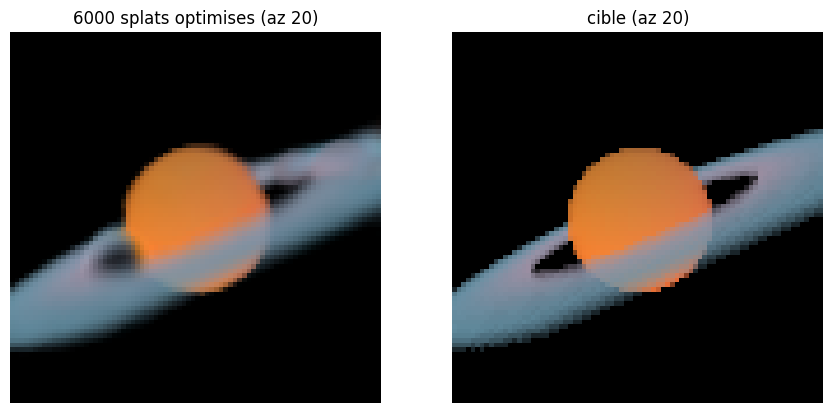

In [12]:
# 6000 splats, 300 iterations, par le moteur.
means_b = torch.nn.Parameter(means6k.clone().to(dev))
lsc_b = torch.nn.Parameter(torch.log(scales6k.clone()).to(dev))
qt_b = torch.nn.Parameter(quats6k.clone().to(dev))
col_b = torch.nn.Parameter(rgb6k.clone().to(dev))
lopa_b = torch.nn.Parameter(torch.logit(opa6k.clone()).to(dev))
opt_b = torch.optim.Adam([
    {'params': [means_b], 'lr': 1e-2},
    {'params': [lsc_b], 'lr': 2e-3},
    {'params': [qt_b], 'lr': 1e-3},
    {'params': [col_b], 'lr': 5e-3},
    {'params': [lopa_b], 'lr': 5e-3},
])
sched_b = torch.optim.lr_scheduler.StepLR(opt_b, step_size=120, gamma=0.5)
t0 = time.time()
for it in range(301):
    opt_b.zero_grad()
    out, _, _ = gsplat.rasterization(means_b, torch.nn.functional.normalize(qt_b, dim=-1),
                                     lsc_b.exp().clamp(min=0.03), torch.sigmoid(lopa_b),
                                     col_b.clamp(0, 1), viewmats, Ks, HW, HW)
    perte_b = F.l1_loss(out.clamp(0, 1), cibles_dev)
    if it < 300:
        perte_b.backward(); opt_b.step(); sched_b.step()
dt_b = time.time() - t0
corr_b = float(torch.corrcoef(torch.stack([out[0].clamp(0, 1).flatten().cpu(), vues_cibles[0].flatten()]))[0, 1])
print(f"6000 splats : 300 iterations en {dt_b:.1f}s — perte {float(perte_b):.4f}, corr az 20 {corr_b:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
axes[0].imshow(out[0].clamp(0, 1).detach().cpu().numpy()); axes[0].set_title("6000 splats optimises (az 20)"); axes[0].axis('off')
axes[1].imshow(vues_cibles[0].numpy()); axes[1].set_title("cible (az 20)"); axes[1].axis('off')
plt.tight_layout(); plt.show()

## 8. Exercices

### Exercice 1 — le rayon écran et les tuiles

Combien de tuiles chaque splat couvre-t-il ? L'écart-type écran d'un splat isotrope d'échelle $s$ vu à profondeur $z$ vaut $\sigma_{px} \approx f \cdot s / z$. Complétez la fonction pour retourner les rayons en pixels (le moteur regroupe les pixels en tuiles de 16×16).

In [13]:
def rayons_ecran_eleve(means, scales, theta, focal=90.0):
    # Renvoie l'ecart-type ecran (en pixels) de chaque splat, approximation perspective.
    # Etape 1 : profondeur z de chaque splat dans le repere camera (reprendre la projection du maison).
    # Etape 2 : sigma_px = focal * scale_moyen / z.
    pass  # TODO etudiant
    print("Exercice a completer")
    return None

### Exercice 2 — le degré 3

Le papier 3DGS monte jusqu'au degré 3. Reprenez le duel de la section 6 avec `deg=3` (coeffs $(N, 16, 3)$, initialisés comme le degré 2 puis zéros) et comparez le gain relatif.

In [14]:
def duel_degre3_eleve():
    # Etape 1 : reprendre optimiser_sh(3) (meme cellule, section 6).
    # Etape 2 : comparer la perte et le L1 sur le masque speculaire a degre 2.
    pass  # TODO etudiant
    print("Exercice a completer")
    return None

### Exercice 3 — la résolution ne coûte (presque) rien

Rendez la vue azimuth 20 à 160×160 (focale doublée : 180, centre 80) avec le nuage optimisé de la section 5, et chronométrez contre le rendu 80×80. Que dit la structure de coût du moteur sur l'effet de la résolution ?

In [15]:
def rendu_160_eleve():
    # Etape 1 : construire K160 = [[180, 0, 80], [0, 180, 80], [0, 0, 1]] et rendre a 160x160.
    # Etape 2 : chronometrer 30 rendus a 160 puis a 80, comparer.
    pass  # TODO etudiant
    print("Exercice a completer")
    return None

In [16]:
# Verification des exercices : affiche "Exercice a completer" tant que le stub est en place.
essais = [
    ("rayons_ecran_eleve", lambda: rayons_ecran_eleve(means0, scales0, theta0)),
    ("duel_degre3_eleve", lambda: duel_degre3_eleve()),
    ("rendu_160_eleve", lambda: rendu_160_eleve()),
]
for nom, fn in essais:
    res = fn()
    etat = "stub (a completer)" if res is None else f"retour {type(res).__name__}"
    print(f"  {nom} : {etat}")
print("Note : les stubs s'executent sans erreur — le carnet reste valide de bout en bout (regle C.1).")

Exercice a completer
  rayons_ecran_eleve : stub (a completer)
Exercice a completer
  duel_degre3_eleve : stub (a completer)
Exercice a completer
  rendu_160_eleve : stub (a completer)
Note : les stubs s'executent sans erreur — le carnet reste valide de bout en bout (regle C.1).


## Ce qu'il faut retenir

- **Un moteur, deux conventions** : le nuage de 3D-03 passe dans `gsplat` après une conversion caméra explicite (`diag(1, -1, -1, 1)`, OpenGL vers OpenCV) — l'oublier rend une image noire *silencieusement*, la scène entière passant derrière la caméra.
- **La parité est mesurée, pas décrétée** : même nuage, mêmes attributs, L1 de l'ordre du centième entre les deux moteurs — l'écart résiduel vit dans les détails (filtre écran, compensation de dilatation).
- **Le coût change de structure** : le maison paie $M \times P$ en dense sur CPU ; le moteur paie la couverture par tuiles, avec culling — le facteur mesuré **grandit** avec la taille du nuage, signature d'un meilleur coût asymptotique.
- **Le moteur rend la boucle praticable** : les 550 itérations qui coûtaient 7 minutes en 3D-03 tiennent en secondes ; la densification et les scènes réelles (des centaines de milliers de splats) entrent dans le champ du possible.
- **SH, le pourquoi** : sur une cible spéculaire, le degré 0 plafonne (une couleur constante par splat ne peut pas briller *ici* et être mat *là*) ; le degré 2 absorbe la dépendance angulaire — gain mesuré, localisé sur les pixels du reflet.
- La convention SH du moteur se **mesure** (splat témoin) avant de s'utiliser — jamais crue sur documentation.

*Note d'exécution* : GPU requis — kernel `gsplat310` (Python 3.10 + torch 2.4.1+cu124 + roue officielle gsplat 1.5.3 ; aucune roue prébuilt Windows plus récente). Déterministe (seed 42) ; ~2-3 min, compilation JIT au premier rendu incluse. La suite — densification adaptative, audit des hyperparamètres — est le sujet de **3D-05**.